# 03 · Федеративное обучение и сравнение
Запустите сначала раздел симуляции и обучения в блокноте 02. Все оценки в этом исследовании синтетические. Три клиента выполняются последовательно в одной среде Colab. Время отражает вычислительную симуляцию, сетевые задержки не моделируются.

Используем FedAvg — локальное обновление общей модели и взвешенное усреднение параметров. Источник метода: [McMahan et al., 2017](https://proceedings.mlr.press/v54/mcmahan17a.html).

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

In [3]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from time import perf_counter
from scipy.special import expit
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, log_loss
import sklearn

root = Path("/content/drive/MyDrive/Colab Notebooks/Spotify_ARD")
out = root / "experiment"
out.mkdir(exist_ok=True)
# Можно открыть блокнот 03 сразу после получения архива результатов.
import zipfile
archive = root / "experiment_results.zip"
if archive.exists() and not (out / "simulation_42.npz").exists():
    with zipfile.ZipFile(archive) as bundle:
        for item in bundle.infolist():
            if Path(item.filename).name != item.filename:
                raise ValueError("Ожидался архив с плоской структурой")
            (out / item.filename).write_bytes(bundle.read(item))
SEEDS = [42, 123, 2026]


In [4]:
def probabilities(X, w):
    return expit(X @ w)

def gradient_step(X, y, w, lr):
    grad = X.T @ (probabilities(X, w) - y) / len(y)
    penalty = 0.001 * w.copy()
    penalty[0] = 0
    return w - lr * (grad + penalty)

def fit_model(X, y, V, vy, lr, clients=None, local_steps=5, rounds=100):
    w = np.zeros(X.shape[1])
    best_w = w.copy()
    best_loss = np.inf
    history = []
    start = perf_counter()
    for round_index in range(rounds):
        if clients is None:
            for _ in range(local_steps):
                w = gradient_step(X, y, w, lr)
        else:
            updates = []
            for ids in clients:
                local_w = w.copy()
                for _ in range(local_steps):
                    local_w = gradient_step(X[ids], y[ids], local_w, lr)
                updates.append(local_w)
            w = np.average(updates, axis=0, weights=[len(ids) for ids in clients])
        loss = log_loss(vy, probabilities(V, w), labels=[0, 1])
        history.append(loss)
        if loss < best_loss:
            best_loss, best_w = loss, w.copy()
    return best_w, best_loss, np.array(history), perf_counter() - start

def metrics(y, p):
    return {"accuracy": accuracy_score(y, p >= 0.5),
            "f1": f1_score(y, p >= 0.5, zero_division=0),
            "roc_auc": roc_auc_score(y, p),
            "log_loss": log_loss(y, p, labels=[0, 1])}

def select_model(X, y, V, vy, clients=None, local_steps=5):
    candidates = []
    elapsed = 0
    for lr in [0.1, 0.3, 1.0]:
        w, loss, curve, seconds = fit_model(X, y, V, vy, lr, clients, local_steps)
        elapsed += seconds
        candidates.append((loss, lr, w, curve, seconds))
    best = min(candidates, key=lambda item: item[0])
    return best, elapsed


### Протокол и контроль корректности
В non-IID сценарии каждый клиент хранит оценки своего слушателя. Для контрольного IID-подобного сценария перемешиваем обучающие записи между тремя равными узлами. Оба сценария используют те же самые примеры и тест. Идентификатор слушателя остаётся признаком.

В каждом раунде сервер отправляет текущие веса, каждый клиент делает пять локальных полных градиентных шагов, затем сервер вычисляет среднее с весом, равным числу локальных записей. Validation loss можно получить суммированием локальных потерь. В этой симуляции validation объединён в памяти для простоты. Test доступен только процедуре итоговой оценки.

Сначала проверим численно, что один локальный шаг с взвешенной агрегацией совпадает с одним централизованным шагом. Затем выполним 100 раундов и тот же подбор скорости по validation.

In [6]:
federated_rows, per_client, curves = [], [], []
for seed in SEEDS:
    d = np.load(out / f"simulation_{seed}.npz")
    X,y,V,vy = d["X_train"],d["y_train"],d["X_val"],d["y_val"]
    native = [np.flatnonzero(d["client_train"]==c) for c in range(3)]
    shuffled = np.array_split(np.random.default_rng(seed).permutation(len(y)),3)
    zero = np.zeros(X.shape[1])
    aggregate = np.average([gradient_step(X[ix],y[ix],zero,0.3) for ix in native],
                           axis=0,weights=[len(ix) for ix in native])
    np.testing.assert_allclose(aggregate,gradient_step(X,y,zero,0.3),atol=1e-12)
    for scenario,clients in [("FedAvg non-IID",native),("FedAvg IID-like",shuffled)]:
        assert np.array_equal(np.sort(np.concatenate(clients)),np.arange(len(y)))
        best,search_seconds = select_model(X,y,V,vy,clients)
        loss,lr,w,curve,seconds = best
        p = probabilities(d["X_test"],w)
        federated_rows.append({"seed":seed,"method":scenario,**metrics(d["y_test"],p),
                              "validation_loss":loss,"lr":lr,"fit_seconds":seconds,
                              "search_seconds":search_seconds})
        for client in range(3):
            mask = d["client_test"]==client
            per_client.append({"seed":seed,"method":scenario,"client":client,
                               **metrics(d["y_test"][mask],p[mask])})
        curves.append((seed,scenario,curve))
        slug = "noniid" if scenario.endswith("non-IID") else "iid"
        np.savez(out / f"fed_{slug}_{seed}.npz",weights=w,curve=curve,lr=lr)
    cw = np.load(out / f"central_{seed}.npz")["weights"]
    cp = probabilities(d["X_test"],cw)
    for client in range(3):
        mask = d["client_test"]==client
        per_client.append({"seed":seed,"method":"Central","client":client,
                           **metrics(d["y_test"][mask],cp[mask])})
print("Эквивалентность одного шага и покрытие обучающих данных проверены.")
print("Параметров:",X.shape[1],"| раундов: 100 | локальных шагов: 5")
print("Передано байт весов за один запуск FedAvg:",100*3*2*X.shape[1]*8)
print("Это отправка и получение float64; метаданные, validation и подбор параметров не включены.")
results = pd.concat([pd.read_csv(out / "central_results.csv"),pd.DataFrame(federated_rows)],ignore_index=True)
results.to_csv(out / "comparison.csv",index=False)
pd.DataFrame(per_client).to_csv(out / "per_client_metrics.csv",index=False)
display(results.round(4))
summary = results.groupby("method")[["accuracy","f1","roc_auc","log_loss","fit_seconds"]].agg(["mean","std"])
display(summary.round(4))
display(pd.DataFrame(per_client).groupby(["method","client"])[["accuracy","log_loss"]].mean().round(4))


,seed,method,accuracy,f1,roc_auc,log_loss,validation_loss,lr,fit_seconds,search_seconds
0,42,Client prior,0.7047,0.5466,0.6824,0.5711,NaN,NaN,0.0000,0.0000
1,42,Central,0.7527,0.5691,0.7742,0.5193,0.5094,1.0,0.1615,0.4894
2,123,Client prior,0.6727,0.5200,0.6536,0.6080,NaN,NaN,0.0000,0.0000
3,123,Central,0.7327,0.5853,0.7966,0.5126,0.5048,1.0,0.1462,0.4721
4,2026,Client prior,0.6240,0.6475,0.6639,0.6114,NaN,NaN,0.0000,0.0000
5,2026,Central,0.6907,0.6548,0.7617,0.5391,0.5271,1.0,0.1404,0.4405
6,42,FedAvg non-IID,0.7533,0.5708,0.7743,0.5192,0.5094,1.0,0.2275,0.6927
7,42,FedAvg IID-like,0.7527,0.5691,0.7743,0.5193,0.5094,1.0,0.2505,0.7623
8,123,FedAvg non-IID,0.7320,0.5839,0.7965,0.5128,0.5049,1.0,0.2496,0.7394
9,123,FedAvg IID-like,0.7327,0.5853,0.7965,0.5126,0.5048,1.0,0.2697,0.7879


accuracy              f1         roc_auc         log_loss         fit_seconds        
                    mean     std    mean     std    mean     std     mean     std        mean     std
method                                                                                               
Central           0.7253  0.0316  0.6031  0.0455  0.7775  0.0176   0.5236  0.0138      0.1494  0.0109
Client prior      0.6671  0.0406  0.5714  0.0673  0.6666  0.0146   0.5968  0.0223      0.0000  0.0000
FedAvg IID-like   0.7251  0.0320  0.6027  0.0449  0.7775  0.0176   0.5236  0.0138      0.2777  0.0320
FedAvg non-IID    0.7251  0.0322  0.6028  0.0446  0.7775  0.0176   0.5237  0.0137      0.2376  0.0112

accuracy  log_loss
method          client                    
Central         0         0.6747    0.5907
                1         0.8053    0.4159
                2         0.6960    0.5643
FedAvg IID-like 0         0.6740    0.5907
                1         0.8053    0.4158
                2         0.6960    0.5643
FedAvg non-IID  0         0.6740    0.5907
                1         0.8060    0.4159
                2         0.6953    0.5644

Эквивалентность одного шага и покрытие обучающих данных проверены.
Параметров: 44 | раундов: 100 | локальных шагов: 5
Передано байт весов за один запуск FedAvg: 211200
Это отправка и получение float64; метаданные, validation и подбор параметров не включены.


### Сходимость и интерпретация
На графике validation log loss. Для всех методов меньшая потеря лучше. Сравнивайте итоговые показатели по одинаковому seed. Повторения независимы по разбиению и ответам, а внутри повторения тест общий.

Протокол проверяет способность воспроизвести заданную модель предпочтений. Его ограничения — три искусственных вкуса, один любимый трек на слушателя, выбранный механизм генерации и отсутствие сетевых отказов. Объединение параметров само по себе не обеспечивает формальных гарантий приватности. Следующий шаг для внешней проверки — реальные оценки пользователей.

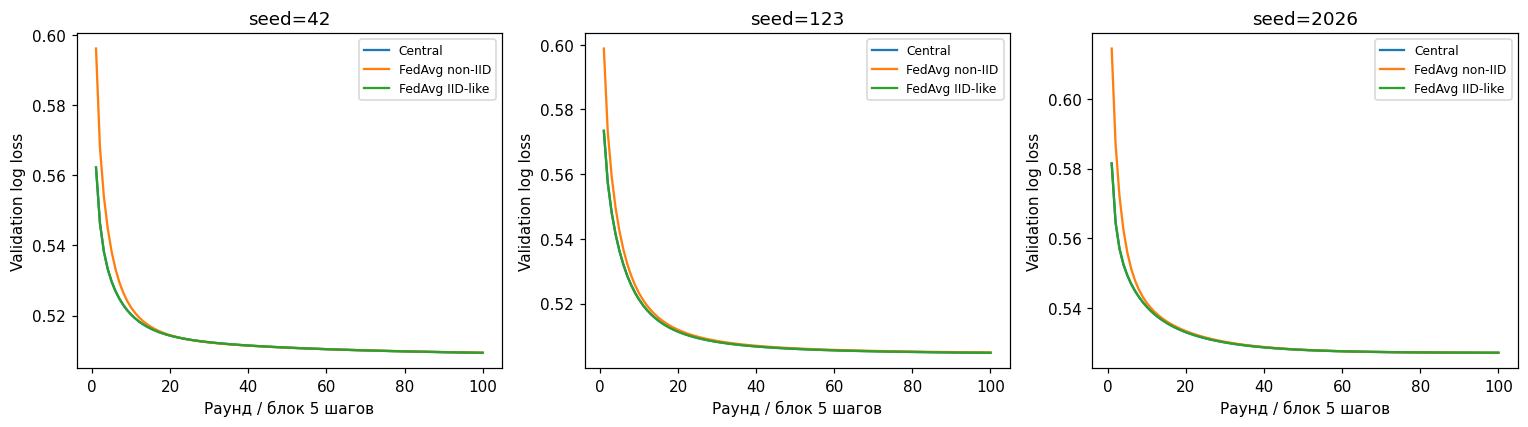

Результаты и параметры сохранены в /workspace/scratch/c9db388f97e2/experiment


In [8]:
fig, axes = plt.subplots(1,3,figsize=(14,4))
for ax,seed in zip(axes,SEEDS):
    ax.plot(np.arange(1,101),np.load(out / f"central_{seed}.npz")["curve"],label="Central")
    for s,name,curve in curves:
        if s==seed:
            ax.plot(np.arange(1,101),curve,label=name)
    ax.set(title=f"seed={seed}",xlabel="Раунд / блок 5 шагов",ylabel="Validation log loss")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(out / "convergence.png",dpi=150)
plt.show()
manifest = {"data":"synthetic ratings on real Spotify features",
            "seeds":SEEDS,"clients":3,"examples_per_client":[2000,500,500],
            "rounds":100,"local_steps":5,"learning_rates":[0.1,0.3,1.0],
            "regularization":0.001,"python":platform.python_version(),
            "numpy":np.__version__,"sklearn":sklearn.__version__,
            "catalog_sha256":hashlib.sha256((root/"data/processed/tracks.csv").read_bytes()).hexdigest()}
(out/"manifest.json").write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
print("Результаты и параметры сохранены в",out)


### Рекомендации обученной модели
Выбираем одного из трёх смоделированных слушателей. Его любимая песня зафиксирована генератором. Модель оценивает весь каталог и возвращает пять композиций с наибольшим прогнозом положительной синтетической оценки. При обучении клиентские примеры уже содержали взаимодействия признаков с ID слушателя. Эта демонстрация относится к известным трём профилям.

Precision@5 ниже рассчитан отдельно на 500 отложенных кандидатах каждого клиента, без использования их ответов при сортировке. В каждой выдаче всего пять ответов, поэтому показатель существенно колеблется.

In [10]:
ranking = []
for seed in SEEDS:
    d = np.load(out / f"simulation_{seed}.npz")
    for method, filename in [("Central",f"central_{seed}.npz"),
                             ("FedAvg non-IID",f"fed_noniid_{seed}.npz")]:
        w = np.load(out/filename)["weights"]
        for client in range(3):
            mask = d["client_test"]==client
            p = probabilities(d["X_test"][mask],w)
            top = np.argsort(-p,kind="stable")[:5]
            ranking.append({"seed":seed,"method":method,"client":client,
                            "precision_at_5":d["y_test"][mask][top].mean()})
ranking = pd.DataFrame(ranking)
ranking.to_csv(out/"ranking_metrics.csv",index=False)
display(ranking.groupby("method").precision_at_5.agg(["mean","std"]).round(3))

def learned_recommend(client=0, seed=42, method="fed", k=5):
    if client not in [0,1,2] or method not in ["fed","central"]:
        raise ValueError("client: 0, 1, 2; method: fed или central")
    d = np.load(out/f"simulation_{seed}.npz")
    name = f"fed_noniid_{seed}.npz" if method=="fed" else f"central_{seed}.npz"
    w = np.load(out/name)["weights"]
    catalog = pd.read_csv(root/"data/processed/tracks.csv").sort_values("track_id")
    catalog["song_key"] = catalog.artists.str.strip().str.casefold()+"\0"+catalog.track_name.str.strip().str.casefold()
    catalog = catalog.drop_duplicates("song_key").set_index("track_id")
    links = pd.read_csv(root/"data/processed/track_genres.csv")
    genres = links.groupby("track_id").track_genre.agg(set)
    features = ["danceability","energy","speechiness","acousticness",
                "instrumentalness","liveness","valence","tempo","loudness"]
    x = catalog[features].copy()
    x.loc[x.tempo.eq(0),"tempo"] = float(d["tempo_median"])
    x[["tempo","loudness"]] = x[["tempo","loudness"]]*d["scale"]+d["min"]
    favorite = str(d["favorite_ids"][client])
    delta = x.sub(x.loc[favorite]).abs().to_numpy()
    g = genres[favorite]
    overlap = np.array([len(g & genres[i])/len(g | genres[i]) for i in x.index])
    base = np.column_stack([delta,overlap])
    onehot = np.eye(3)[np.full(len(x),client)]
    X = np.column_stack([np.ones(len(x)),base,onehot,
                        (base[:,:,None]*onehot[:,None,:]).reshape(len(x),-1)])
    p = probabilities(X,w)
    p[x.index.get_loc(favorite)] = -np.inf
    order = np.argsort(-p,kind="stable")[:k]
    result = catalog.iloc[order][["track_name","artists"]].copy()
    result["model_probability"] = p[order]
    print("Любимый трек:",catalog.loc[favorite,"track_name"],"—",catalog.loc[favorite,"artists"])
    return result.reset_index()

display(learned_recommend(client=0))


,mean,std
method,,
Central,0.889,0.145
FedAvg non-IID,0.889,0.145


,track_id,track_name,artists,model_probability
0,16JJiVvV0cBmo93lIivZKq,Ultimate Devotion,Strung Out,0.801464
1,4h8Eo8YuHropo5SYRSBWEe,En el Séptimo Día (SEP7IMO DIA),Soda Stereo,0.785600
2,7ycK2uijskzxp4cGpGNoCi,Under The Knife,Rise Against,0.783945
3,5obwLR73JZh0JFHRbhgg9s,Pills & Smoke,Swingin' Utters,0.780607
4,2JF6XTiPGGbYOXsLbAnTWx,Count Your Bruises,The Flatliners,0.779540


Любимый трек: Sunshine — Samiam


### Полученные результаты
В трёх повторениях средняя Accuracy централизованной модели составила 0,7253, FedAvg с разделением по слушателям — 0,7251, базового прогноза по клиентской доле — 0,6671. Средняя ROC AUC обученных моделей около 0,7775. Близость результатов относится к данному объёму, представлению профилей и генератору. Перемешивание клиентских данных почти не изменило итоговое качество.

Все модели линейные по подготовленным признакам, задача невелика, а каждому клиенту доступен собственный блок взаимодействий. Поэтому расхождение методов здесь мало; этот результат не доказывает равенство методов для других моделей или распределений.

## Парные графики обучающих данных клиентов
У нас клиент хранит оценки пар «любимый трек — кандидат». Поэтому для клиентских графиков используются реальные входы обученной модели — абсолютные различия признаков (Δ) этих двух треков. Tempo и loudness предварительно масштабированы параметрами train. Пять выбранных разностей входят в модель наряду с остальными признаками.

Показан non-IID сценарий для seed=42, по 2000 обучающих оценок на клиента. Оси всех трёх матриц согласованы. Валидация и тест здесь не показаны. У разных клиентов могут встречаться одинаковые кандидаты; их оценки относятся к разным слушателям. Это распределение клиентских обучающих примеров, а не разбиение всего каталога на три равные части.

Разные распределения отражают выбранные любимые треки и механизм генерации примеров. Подписи явно указывают синтетический характер оценок. Изображения сохраняются в figures.


In [13]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project = Path("/content/drive/MyDrive/Colab Notebooks/Spotify_ARD")
figures = project / "figures"
figures.mkdir(exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})

def pair_matrix(frame, fields, title, subtitle, filename, color="#2879ae", limits=None):
    # Диагональ использует все строки, scatter — воспроизводимую подвыборку.
    sample = frame.sample(min(3000, len(frame)), random_state=42)
    count = len(fields)
    fig, axes = plt.subplots(count, count, figsize=(12, 11))
    for row, vertical in enumerate(fields):
        for col, horizontal in enumerate(fields):
            ax = axes[row, col]
            if row == col:
                ax.hist(frame[horizontal].dropna(), bins=32, color=color, alpha=0.85,
                        range=None if limits is None else limits[horizontal])
            else:
                ax.scatter(sample[horizontal], sample[vertical], s=3, alpha=0.18,
                           color=color, linewidths=0, rasterized=True)
                if limits:
                    ax.set_ylim(*limits[vertical])
            if limits:
                ax.set_xlim(*limits[horizontal])
            ax.spines[["top","right"]].set_visible(False)
            ax.tick_params(labelsize=7, length=2)
            ax.grid(alpha=0.12)
            if row == count-1:
                ax.set_xlabel(horizontal, fontsize=10)
            else:
                ax.tick_params(labelbottom=False)
            if col == 0:
                ax.set_ylabel(vertical if row != col else "Число записей", fontsize=10)
            else:
                ax.tick_params(labelleft=False)
    fig.suptitle(title, x=0.08, y=0.98, ha="left", fontsize=21, fontweight="bold")
    fig.text(0.08, 0.94, subtitle, ha="left", fontsize=11, color="#455365")
    fig.text(0.08, 0.025,
             f"Диагональ — распределения всех {len(frame):,} записей; "
             f"вне диагонали — {len(sample):,} точек. Зерно выборки 42.",
             fontsize=10, color="#455365")
    fig.subplots_adjust(left=0.08,right=0.98,top=0.90,bottom=0.09,hspace=0.17,wspace=0.17)
    fig.savefig(figures / (filename+".png"), dpi=300, facecolor="white")
    fig.savefig(figures / (filename+".pdf"), dpi=200, facecolor="white")
    plt.show()


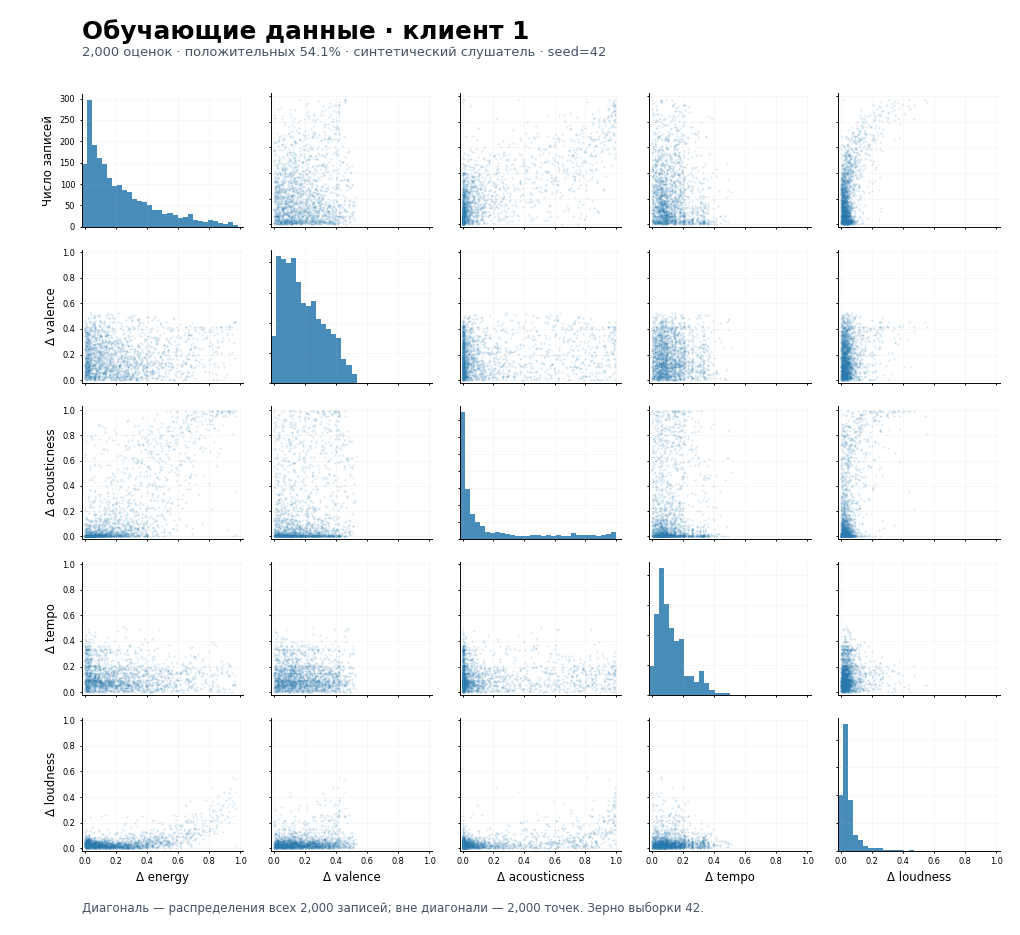

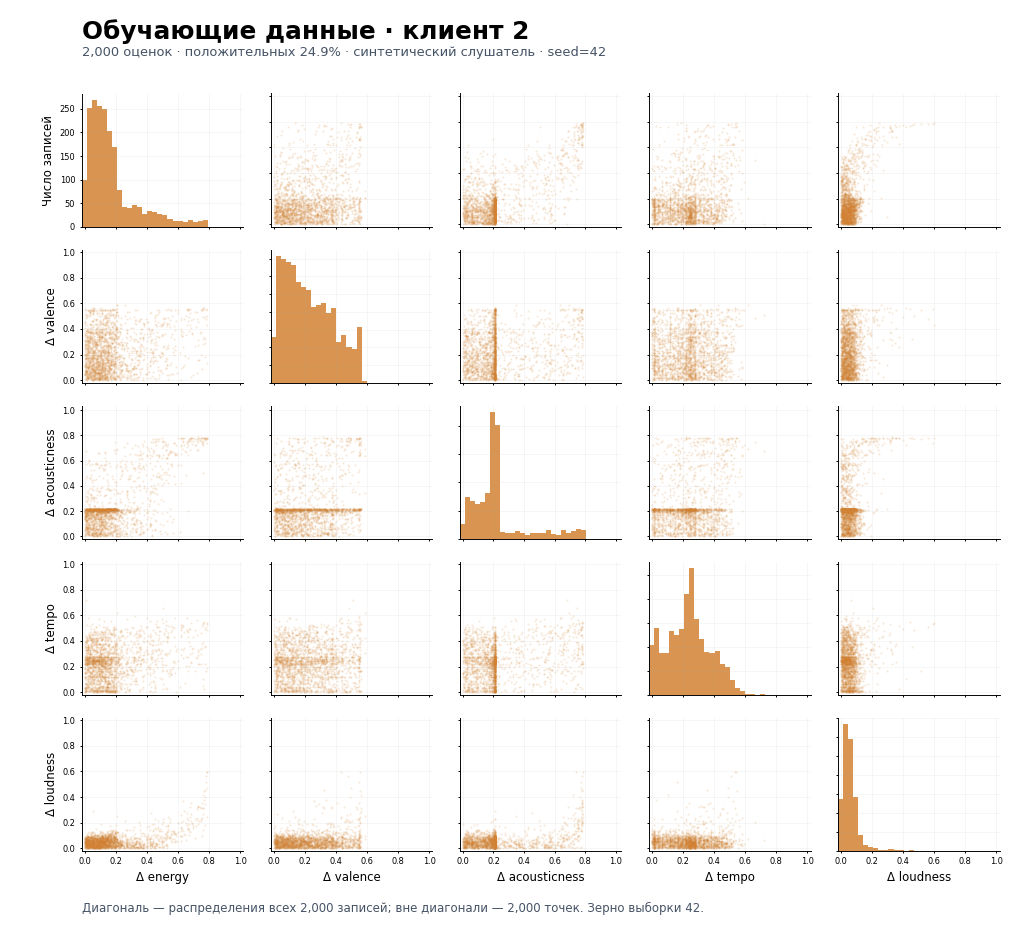

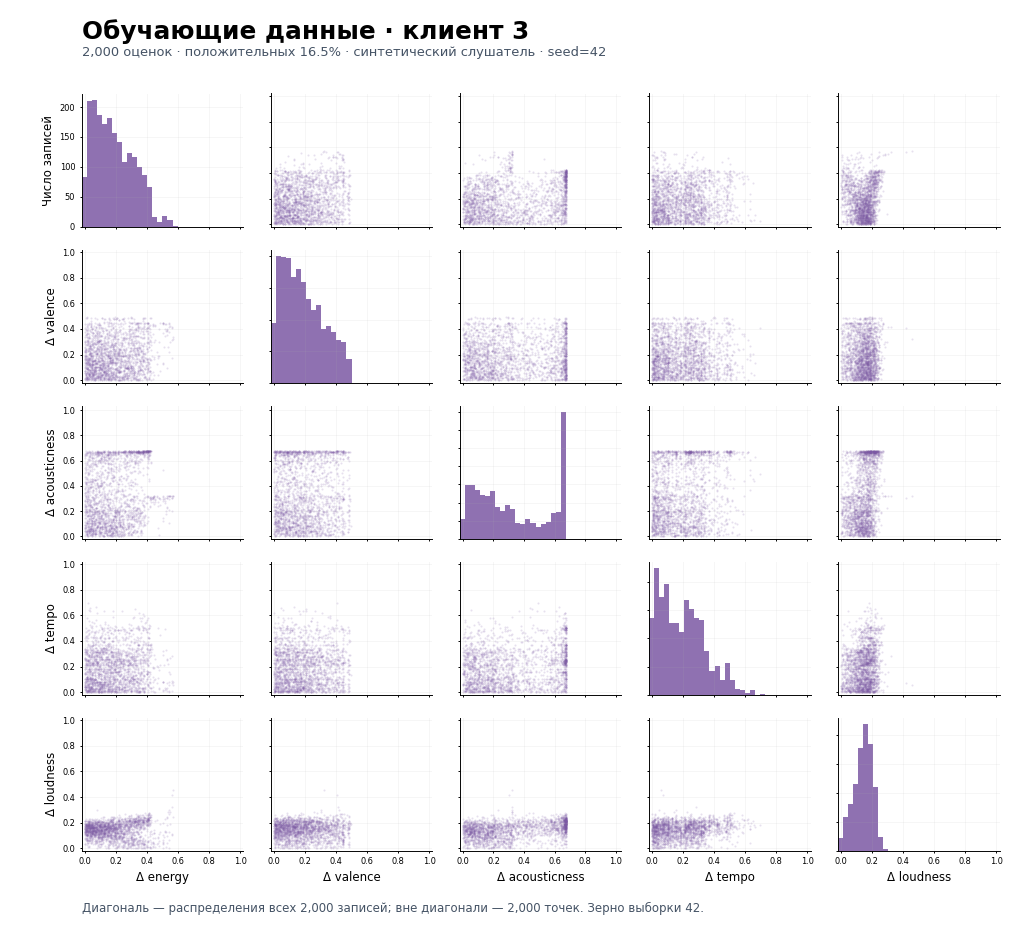

Три клиента по 2000 обучающих оценок; всего 6000.


In [14]:
import zipfile
experiment = project / "experiment"
if not (experiment / "simulation_42.npz").exists():
    experiment.mkdir(exist_ok=True)
    with zipfile.ZipFile(project / "experiment_results.zip") as bundle:
        name = "simulation_42.npz"
        (experiment / name).write_bytes(bundle.read(name))
data = np.load(experiment / "simulation_42.npz")
# X = [1, девять разностей аудиопризнаков, жанровое пересечение, ...].
selected = {"Δ energy":2, "Δ valence":7, "Δ acousticness":4,
            "Δ tempo":8, "Δ loudness":9}
combined = pd.DataFrame({name:data["X_train"][:,i] for name,i in selected.items()})
limits = {col:(-0.02,max(1.02,combined[col].max()*1.04)) for col in combined}
colors = ["#2879ae","#d28131","#7b58a4"]
for client in range(3):
    mask = data["client_train"]==client
    frame = combined.loc[mask]
    positive = data["y_train"][mask].mean()
    pair_matrix(frame, list(selected),
                f"Обучающие данные · клиент {client+1}",
                f"{len(frame):,} оценок · положительных {positive:.1%} · "
                "синтетический слушатель · seed=42",
                f"0{client+3}_client_{client+1}",colors[client],limits)
print("Три клиента по 2000 обучающих оценок; всего 6000.")
